# Day 5: Can we trust the baseline?
Nouman Bashir · MUN Economics · 16 October 2026

Open in Colab and choose **Runtime > Run all**. This notebook carries its source files; no other upload is needed. It uses NumPy, SciPy and Matplotlib. No GPU is required.

We keep the verified Day 4 solver and test it more carefully. The short cells below explain the experiment. The supporting source cell is collapsed so you can focus on the results first. The full code is in the downloadable bundle.

**What we will check:** finer wealth grids, tighter stopping rules, alternative inputs, and the four Example 5 Pareto weights. A reported limitation stays visible even when the baseline audit passes.

## 1. Prepare the supporting code
This cell writes the exact solver, audit and notes into `day5_work`. It does not download code or change your GitHub repository. Repeating Run all overwrites this working folder's files and results. Save your executed notebook and the final ZIP yourself.

In [1]:
from pathlib import Path
import csv
import importlib.util
import json
import sys

# Preserve the audited source files so this notebook works without other uploads.
source_files = {'day04/day4_example.py': '"""Day 4 notebook definitions, with a local command-line entry point."""\n\nfrom dataclasses import asdict, dataclass, field, replace\nfrom datetime import datetime, timezone\nfrom pathlib import Path\nfrom zipfile import ZIP_DEFLATED, ZipFile\nimport csv\nimport json\nimport platform\nimport sys\n\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport scipy\nfrom scipy.integrate import quad\nfrom scipy.optimize import Bounds, LinearConstraint, brentq, linprog, minimize\n\n# Optional Colab support is imported once, alongside every other dependency.\ntry:\n    from google.colab import files as colab_files\nexcept ImportError:\n    colab_files = None\n\n# Class: The single place to change experiment settings.\n@dataclass(frozen=True)\nclass ExperimentConfig:\n    """The single place to change experiment settings."""\n    states: int = 400\n    gap_tolerance: float = 5e-6\n    allocation_tolerance: float = 0.0025\n    feasibility_tolerance: float = 1e-10\n    roundoff_tolerance: float = 1e-12\n    max_updates: int = 20000\n    validation_seed: int = 20261009\n    output_directory: str = "day4_results"\n    agent_types: tuple = ("h2", "h2", "h1", "h1", "h1", "h1", "h1", "h2")\n    pareto_weights: tuple = (1.,) * 8\n\n    # Function: Check that the grid size, update limit, tolerances, and output folder are valid.\n    def __post_init__(self):\n        if not isinstance(self.states, int) or self.states < 1:\n            raise ValueError("states must be a positive integer")\n        if not isinstance(self.max_updates, int) or self.max_updates < 0:\n            raise ValueError("max_updates must be a nonnegative integer")\n        tolerances = (self.gap_tolerance, self.allocation_tolerance,\n                      self.feasibility_tolerance, self.roundoff_tolerance)\n        if not all(np.isfinite(x) and x > 0 for x in tolerances):\n            raise ValueError("All tolerances must be finite and positive")\n        if not self.output_directory:\n            raise ValueError("Choose an output directory")\n\n# Class: Hold model inputs and calculate utility, welfare, and its gradient.\n@dataclass(frozen=True)\nclass RiskSharingModel:\n    """Hold model inputs and calculate utility, welfare, and its gradient."""\n    wealth: np.ndarray\n    ranks: np.ndarray\n    probabilities: np.ndarray\n    weights: np.ndarray\n    agent_types: tuple\n    offsets: np.ndarray = field(init=False, repr=False)\n\n    # Function: Validate and protect model inputs, then calculate the utility offsets once.\n    def __post_init__(self):\n        # Copy and protect inputs so later cells cannot accidentally change them.\n        for name in ("wealth", "ranks", "probabilities", "weights"):\n            value = np.array(getattr(self, name), dtype=float, copy=True)\n            if value.ndim != 1 or not value.size or not np.isfinite(value).all():\n                raise ValueError(f"{name} must be a finite, nonempty vector")\n            value.setflags(write=False)\n            object.__setattr__(self, name, value)\n        types = tuple(self.agent_types)\n        object.__setattr__(self, "agent_types", types)\n        if self.ranks.shape != self.wealth.shape or self.probabilities.shape != self.wealth.shape:\n            raise ValueError("One rank and probability are required per wealth state")\n        if np.any(self.wealth < 0) or np.any(np.diff(self.wealth) < 0):\n            raise ValueError("Wealth must be nonnegative and nondecreasing")\n        if np.any((self.ranks <= 0) | (self.ranks >= 1)) or np.any(np.diff(self.ranks) <= 0):\n            raise ValueError("Ranks must increase strictly within (0, 1)")\n        if np.any(self.probabilities < 0) or not np.isclose(self.probabilities.sum(), 1, rtol=0, atol=1e-12):\n            raise ValueError("Probabilities must be nonnegative and sum to one")\n        if np.any(self.weights <= 0) or len(types) != self.weights.size:\n            raise ValueError("One positive Pareto weight is required per agent")\n        if any(t not in ("h1", "h2") for t in types):\n            raise ValueError("Each agent type must be h1 or h2")\n        powers = np.array([.5 if t == "h1" else 2/3 for t in types])\n        offsets = 1 + self.ranks[:, None] ** powers[None, :]\n        offsets.setflags(write=False)\n        object.__setattr__(self, "offsets", offsets)\n\n    # Function: Build a midpoint wealth grid from settings and return a model object.\n    @classmethod\n    def from_config(cls, config, states=None):\n        """Generate the midpoint grid; no uploaded data are needed."""\n        count = config.states if states is None else states\n        ranks = (np.arange(count) + .5) / count\n        return cls(ranks.copy(), ranks, np.full(count, 1/count),\n                   config.pareto_weights, config.agent_types)\n\n    # Function: Return the number of states and agents as a pair: (states, agents).\n    @property\n    def shape(self):\n        return self.wealth.size, self.weights.size  # (states, agents)\n\n    # Function: Check that shares have the right dimensions and are finite and nonnegative.\n    def consumption(self, values):\n        """Validate an allocation\'s shape and utility domain."""\n        c = np.asarray(values, dtype=float)\n        if c.shape != self.shape or not np.isfinite(c).all() or np.any(c < 0):\n            raise ValueError(f"Consumption must be finite, nonnegative, and shape {self.shape}")\n        return c\n\n    # Function: Return total expected weighted satisfaction as one welfare number.\n    def objective(self, consumption):\n        c = self.consumption(consumption)\n        return float(np.sum(self.probabilities[:, None] * self.weights[None, :]\n                            * np.log(self.offsets + c)))\n\n    # Function: Return the extra welfare benefit per unit of consumption at every table entry.\n    def gradient(self, consumption):\n        c = self.consumption(consumption)\n        return self.probabilities[:, None] * self.weights[None, :] / (self.offsets + c)\n\n    # Function: Create a feasible starting table by dividing each state\'s wealth equally.\n    def equal_sharing(self):\n        return np.repeat(self.wealth[:, None] / self.shape[1], self.shape[1], axis=1)\n\n# Class: Own budget balance, nonnegativity, monotonicity, and the linear oracle.\nclass AllocationConstraints:\n    """Own budget balance, nonnegativity, monotonicity, and the linear oracle."""\n    # Function: Store the wealth vector, required table shape, and feasibility tolerance.\n    def __init__(self, model, tolerance=1e-10):\n        self.wealth = model.wealth\n        self.shape = model.shape\n        self.tolerance = tolerance\n\n    # Function: Check budget balance, nonnegative shares, and monotonicity; return residuals.\n    def check(self, allocation):\n        c = np.asarray(allocation, dtype=float)\n        if c.shape != self.shape or not np.isfinite(c).all():\n            raise AssertionError("Allocation has an invalid shape or nonfinite values")\n        increments = np.diff(np.vstack((np.zeros((1, self.shape[1])), c)), axis=0)\n        residuals = {"budget_residual": float(np.max(abs(c.sum(axis=1) - self.wealth))),\n                     "minimum_consumption": float(c.min()),\n                     "minimum_increment": float(increments.min())}\n        if (residuals["budget_residual"] > self.tolerance\n                or min(residuals["minimum_consumption"], residuals["minimum_increment"]) < -self.tolerance):\n            raise AssertionError(residuals)\n        return residuals\n\n    # Function: Find the best feasible allocation for the supplied linear gradient scores.\n    def linear_oracle(self, gradient):\n        """Allocate wealth increments using tail sums of the gradient."""\n        g = np.asarray(gradient, dtype=float)\n        if g.shape != self.shape or not np.isfinite(g).all():\n            raise ValueError("Gradient must be finite and match the allocation shape")\n        scores = np.cumsum(g[::-1], axis=0)[::-1]\n        winners = scores == scores.max(axis=1, keepdims=True)\n        wealth_increments = np.diff(np.r_[0., self.wealth])\n        # Share exact ties equally; cumulative sums reconstruct consumption.\n        increments = wealth_increments[:, None] * winners / winners.sum(axis=1, keepdims=True)\n        return np.cumsum(increments, axis=0)\n\n# Class: Keep the solution and convergence evidence together.\n@dataclass\nclass SolverResult:\n    """Keep the solution and convergence evidence together."""\n    allocation: np.ndarray\n    history: list\n    converged: bool\n\n    # Function: Read the last saved iteration without copying the history.\n    @property\n    def final(self):\n        return self.history[-1]\n\n\n# Class: Improve a feasible allocation using gradients, an oracle, and line search.\nclass FrankWolfeSolver:\n    """Improve a feasible allocation using gradients, an oracle, and line search."""\n    # Function: Connect this solver to its model, feasibility rules, and settings.\n    def __init__(self, model, constraints, config):\n        self.model = model\n        self.constraints = constraints\n        self.config = config\n\n    # Function: Use derivative signs and bisection to choose a step between zero and one.\n    def _line_search(self, allocation, direction):\n        # A positive derivative means a slightly larger step improves welfare.\n        def slope(step):\n            return float(np.sum(self.model.gradient(allocation + step*direction) * direction))\n        if slope(0) <= 0:\n            return 0.\n        if slope(1) >= 0:\n            return 1.\n        left, right = 0., 1.\n        for _ in range(42):\n            middle = (left + right) / 2\n            if slope(middle) > 0:\n                left = middle\n            else:\n                right = middle\n        return (left + right) / 2\n\n    # Function: Repeat oracle and line-search steps until the welfare gap is small or the run stops.\n    def solve(self):\n        c, history = self.model.equal_sharing(), []\n        for iteration in range(self.config.max_updates + 1):\n            residuals = self.constraints.check(c)\n            value, gradient = self.model.objective(c), self.model.gradient(c)\n            candidate = self.constraints.linear_oracle(gradient)\n            self.constraints.check(candidate)\n            direction = candidate - c\n            gap = float(np.sum(gradient * direction))\n            if gap < -self.config.roundoff_tolerance:\n                raise AssertionError("An exact linear oracle cannot have a negative gap")\n            gap = max(gap, 0.)  # clip harmless floating point rounding only\n            record = {"iteration": iteration, "welfare": value, "gap": gap,\n                      "upper_bound": value + gap, **residuals, "step": None}\n            history.append(record)\n            converged = gap <= self.config.gap_tolerance\n            if converged or iteration == self.config.max_updates:\n                return SolverResult(c, history, converged)\n            record["step"] = self._line_search(c, direction)\n            updated = c + record["step"] * direction\n            self.constraints.check(updated)\n            if self.model.objective(updated) < value - self.config.roundoff_tolerance:\n                raise AssertionError("Welfare decreased")\n            if record["step"] == 0 or np.array_equal(updated, c):\n                return SolverResult(c, history, False)\n            c = updated\n\n# Class: Supply the analytic answer and a separate scalar-equation check.\nclass Example2Benchmark:\n    """Supply the analytic answer and a separate scalar-equation check."""\n    # Function: Identify the two agent groups and reject settings outside this analytic formula.\n    def __init__(self, model):\n        types = np.array(model.agent_types)\n        self.h1 = np.flatnonzero(types == "h1")\n        self.h2 = np.flatnonzero(types == "h2")\n        if model.shape[1] != 8 or len(self.h1) != 5 or len(self.h2) != 3:\n            raise ValueError("Example 2 requires five h1 and three h2 agents")\n        if not np.array_equal(model.weights, np.ones(8)):\n            raise ValueError("The group formula requires unit Pareto weights")\n        if not np.array_equal(model.wealth, model.ranks) or np.any(model.wealth > 1):\n            raise ValueError("The group formula requires rank = wealth in [0,1]")\n        self.model = model\n\n    # Function: Solve the boundary equation and return the wealth where h1 consumption activates.\n    @property\n    def activation(self):\n        # t = wealth**(1/6) turns the boundary condition into a cubic equation.\n        # brentq varies t until this expression equals zero; t**6 gives wealth.\n        return brentq(\n            lambda t: t**3 + 3*t - 3,  # Input: t. Output: the cubic equation\'s residual.\n            0., 1., xtol=1e-14) ** 6\n\n    # Function: Return the exact per-agent consumption table for specified wealth values.\n    def allocation(self, wealth):\n        s = np.asarray(wealth, dtype=float)\n        if s.ndim != 1 or not np.isfinite(s).all() or np.any((s < 0) | (s > 1)):\n            raise ValueError("Benchmark wealth must be a vector in [0,1]")\n        b = np.maximum((s + 3*(s**(2/3) - np.sqrt(s))) / 8, 0.)\n        a = (s - 5*b) / 3\n        result = np.empty((len(s), 8))\n        result[:, self.h1], result[:, self.h2] = b[:, None], a[:, None]\n        return result\n\n    # Function: Find each state\'s allocation by solving a separate marginal-utility equation.\n    def scalar_allocation(self):\n        """Solve marginal utility balance without using the group formula."""\n        allocations = []\n        for wealth, base in zip(self.model.wealth, self.model.offsets):\n            weights = self.model.weights\n            # x is a trial common weighted marginal utility. weights/x - base\n            # gives each share; maximum(..., 0) prevents negative consumption.\n            # The root makes total allocated consumption equal available wealth.\n            mu = brentq(\n                lambda x: np.maximum(weights/x - base, 0).sum() - wealth,  # Return total shares minus wealth.\n                1e-6, float(np.max(weights/base)), xtol=1e-14)\n            allocations.append(np.maximum(weights/mu - base, 0))\n        return np.array(allocations)\n\n    # Function: Build theoretical predictions at selected wealth values before optimization.\n    def prediction_table(self):\n        wealth = np.array([0., .1, .2, self.activation, .3, .35, .5, .75, 1.])\n        allocation = self.allocation(wealth)\n        return [{"wealth": s, "b_each_h1": row[self.h1[0]],\n                 "a_each_h2": row[self.h2[0]], "total": row.sum()}\n                for s, row in zip(wealth, allocation)]\n\n# Build the budget and monotonicity matrices used by the independent SciPy solvers.\ndef validation_matrices(model):\n    states, agents = model.shape\n    budget = np.kron(np.eye(states), np.ones((1, agents)))\n    differences = np.eye(states) - np.eye(states, k=-1)\n    return budget, np.kron(differences, np.eye(agents))\n\n# Class: Compare the model\'s gradient with a small numerical change in welfare.\n@dataclass\nclass GradientCheck:\n    """Compare the model\'s gradient with a small numerical change in welfare."""\n    config: ExperimentConfig\n\n    # Function: Compare the analytic gradient with a centered finite-difference welfare change.\n    def run(self, model, rng):\n        c = model.equal_sharing()\n        increments = rng.dirichlet(np.ones(8), 6) * np.diff(np.r_[0., model.wealth])[:, None]\n        direction = np.cumsum(increments, axis=0) - c\n        step = 1e-5\n        difference = (model.objective(c + step*direction) - model.objective(c - step*direction))/(2*step)\n        error = abs(difference - np.sum(model.gradient(c)*direction))\n        assert error < 1e-8\n        return {"gradient_absolute_error": float(error)}\n\n# Class: Compare the linear oracle with HiGHS in thirteen small cases.\n@dataclass\nclass OracleCheck:\n    """Compare the linear oracle with HiGHS in thirteen small cases."""\n    config: ExperimentConfig\n\n    # Function: Compare our linear oracle against HiGHS in ten random and three special cases.\n    def run(self, model, rng):\n        constraints = AllocationConstraints(model, self.config.feasibility_tolerance)\n        budget, monotone = validation_matrices(model)\n        c = model.equal_sharing()\n        cases = [rng.normal(size=model.shape) for _ in range(10)]\n        cases += [-np.ones_like(c), np.zeros_like(c), np.tile(np.arange(6.)[:, None], (1, 8))]\n        errors = []\n        for gradient in cases:\n            independent = linprog(-gradient.ravel(), A_ub=-monotone, b_ub=np.zeros(c.size),\n                                  A_eq=budget, b_eq=model.wealth, bounds=(0, None), method="highs")\n            assert independent.success, independent.message\n            candidate = constraints.linear_oracle(gradient)\n            constraints.check(candidate)\n            errors.append(abs(float(np.sum(gradient*candidate)) + independent.fun))\n        assert max(errors) < 1e-10\n        for gradient in cases[-3:]:\n            assert np.max(abs(constraints.linear_oracle(gradient) - c)) < 1e-12\n        return {"oracle_lp_cases": len(cases), "maximum_oracle_value_error": max(errors)}\n\n# Class: Compare the small-grid solver with SLSQP and the analytic benchmark.\n@dataclass\nclass OptimizerCheck:\n    """Compare the small-grid solver with SLSQP and the analytic benchmark."""\n    config: ExperimentConfig\n\n    # Function: Compare a small-grid solver result with SLSQP, the analytic answer, and scalar roots.\n    def run(self, model):\n        constraints = AllocationConstraints(model, self.config.feasibility_tolerance)\n        solver = FrankWolfeSolver(model, constraints, self.config).solve()\n        assert solver.converged\n        budget, monotone = validation_matrices(model)\n        # SLSQP expects flat shares x; reshape restores the (states, agents) table.\n        # Negative welfare converts maximization into minimization.\n        independent = minimize(\n            lambda x: -model.objective(x.reshape(model.shape)),  # Input flat shares; return negative welfare.\n            model.equal_sharing().ravel(),\n            jac=lambda x: -model.gradient(x.reshape(model.shape)).ravel(),  # Return the flat gradient of negative welfare.\n            method="SLSQP", constraints=[LinearConstraint(budget, model.wealth, model.wealth),\n                                         LinearConstraint(monotone, 0, np.inf)],\n            bounds=Bounds(0, np.inf), options={"ftol": 1e-12, "maxiter": 1000})\n        assert independent.success, independent.message\n        direct = independent.x.reshape(model.shape)\n        constraints.check(direct)\n        benchmark = Example2Benchmark(model)\n        exact = benchmark.allocation(model.wealth)\n        direct_error = abs(model.objective(direct) - model.objective(exact))\n        solver_error = model.objective(exact) - model.objective(solver.allocation)\n        root_error = float(np.max(abs(benchmark.scalar_allocation() - exact)))\n        assert direct_error < 1e-9 and root_error < 1e-10\n        assert -1e-12 <= solver_error <= solver.final["gap"] + 1e-12\n        report = {"small_slsqp_welfare_error": direct_error, "small_solver_welfare_error": solver_error,\n                  "small_solver_gap": solver.final["gap"], "scalar_root_allocation_error": root_error}\n        return report, direct\n\n# Class: Verify that the feasibility checker rejects three deliberately invalid allocations.\n@dataclass\nclass FeasibilityCheck:\n    """Verify that the feasibility checker rejects three deliberately invalid allocations."""\n    config: ExperimentConfig\n\n    # Function: Confirm that budget, negative-share, and monotonicity violations are all rejected.\n    def run(self, model, direct):\n        constraints = AllocationConstraints(model, self.config.feasibility_tolerance)\n        invalid = [direct + .01, direct.copy(), direct.copy()]\n        invalid[1][0] = [-.01, model.wealth[0]+.01, 0, 0, 0, 0, 0, 0]\n        invalid[2][1] = [model.wealth[1], 0, 0, 0, 0, 0, 0, 0]\n        rejections = 0\n        for allocation in invalid:\n            try:\n                constraints.check(allocation)\n            except AssertionError:\n                rejections += 1\n        assert rejections == len(invalid)\n        return {"feasibility_rejections": rejections}\n\n# Class: Run the four checks and combine their small result dictionaries.\n@dataclass\nclass NumericalValidator:\n    """Run the four checks and combine their small result dictionaries."""\n    config: ExperimentConfig\n\n    # Function: Run every independent check in a fixed order and combine their result dictionaries.\n    def run(self):\n        rng = np.random.default_rng(self.config.validation_seed)\n        small = RiskSharingModel.from_config(self.config, states=6)\n        small = replace(small, ranks=small.ranks**.8,\n                        probabilities=np.arange(1., 7.)/21, weights=np.linspace(.7, 1.4, 8))\n        report = {"passed": True}\n        report.update(GradientCheck(self.config).run(small, rng))\n        report.update(OracleCheck(self.config).run(small, rng))\n        model = RiskSharingModel.from_config(self.config, states=12)\n        optimizer_report, direct = OptimizerCheck(self.config).run(model)\n        report.update(optimizer_report)\n        report.update(FeasibilityCheck(self.config).run(model, direct))\n        return report\n\n# Class: Calculate acceptance checks and distinguish grid error from optimization error.\nclass ResultAnalysis:\n    """Calculate acceptance checks and distinguish grid error from optimization error."""\n    # Function: Keep a reference to the experiment whose numerical evidence will be analyzed.\n    def __init__(self, experiment):\n        self.experiment = experiment\n\n    # Function: Calculate allocation errors, seven acceptance gates, and the continuous reference.\n    def evaluate(self):\n        e = self.experiment\n        model, benchmark, result = e.model, e.benchmark, e.result\n        exact_value = model.objective(e.exact)\n        welfare_error = exact_value - result.final["welfare"]\n        allocation_error = float(np.max(abs(result.allocation - e.exact)))\n        symmetry_error = max(float(np.ptp(result.allocation[:, group], axis=1).max())\n                             for group in (benchmark.h1, benchmark.h2))\n        root_error = float(np.max(abs(benchmark.scalar_allocation() - e.exact)))\n        inactive = result.allocation[model.wealth <= benchmark.activation][:, benchmark.h1]\n        leakage = float(inactive.max()) if inactive.size else 0.\n        tolerance = e.config.roundoff_tolerance\n        gates = {"converged": result.converged,\n                 "allocation_matches": allocation_error <= e.config.allocation_tolerance,\n                 "analytic_inside_certificate": -tolerance <= welfare_error <= result.final["gap"] + tolerance,\n                 "scalar_root_matches": root_error < 1e-10,\n                 "identical_agents_match": symmetry_error < 1e-12,\n                 "welfare_nondecreasing": bool(np.all(np.diff([r["welfare"] for r in result.history]) >= -tolerance)),\n                 "inactive_region_matches": leakage <= e.config.allocation_tolerance}\n        # Function: Return total analytic utility at one continuous wealth value for integration.\n        def continuous_utility(wealth):\n            row = benchmark.allocation(np.array([wealth]))[0]\n            return (5*np.log1p(np.sqrt(wealth) + row[benchmark.h1[0]])\n                    + 3*np.log1p(wealth**(2/3) + row[benchmark.h2[0]]))\n        continuous, integration_error = quad(continuous_utility, 0., 1., points=[benchmark.activation],\n                                             epsabs=1e-11, epsrel=1e-11, limit=200)\n        return {"status": "PASS" if all(gates.values()) else "FAIL",\n                "completed_at_utc": datetime.now(timezone.utc).isoformat(),\n                "config": asdict(e.config), "iterations": len(result.history)-1,\n                "final": result.final, "analytic_grid_welfare": exact_value,\n                "welfare_error": welfare_error, "maximum_allocation_error": allocation_error,\n                "symmetry_error": symmetry_error, "analytic_feasibility": e.constraints.check(e.exact),\n                "scalar_root_allocation_error": root_error, "analytic_activation_wealth": benchmark.activation,\n                "maximum_h1_leakage_below_activation": leakage,\n                "continuous_welfare_reference": continuous, "quad_estimated_absolute_error": integration_error,\n                "midpoint_grid_minus_continuous_reference": exact_value - continuous, "gates": gates,\n                "certificate_scope": "Concave optimization on the fixed finite grid; floating point accuracy",\n                "day4_deliverables": "COMPLETE" if all(gates.values()) else "INCOMPLETE",\n                "review_note": "Both roles delegated; no blind comparison or personal review by Parsa claimed"}\n\n# Class: Display the stored evidence and build the comparison table.\nclass ResultTables:\n    """Display the stored evidence and build the comparison table."""\n    # Function: Keep a reference to the experiment whose tables will be displayed.\n    def __init__(self, experiment):\n        self.experiment = experiment\n\n    # Function: Print selected numeric columns with aligned headings and eight decimal places.\n    @staticmethod\n    def _print_table(rows, columns):\n        print("  ".join(f"{column:>16}" for column in columns))\n        for row in rows:\n            print("  ".join(f"{row[column]:16.8f}" for column in columns))\n\n    # Function: Build numerical-versus-analytic comparisons at selected midpoint states.\n    def comparison_table(self):\n        e = self.experiment\n        e._require_result()\n        wealth, b = e.model.wealth, e.benchmark\n        points = [0., .1, .2, b.activation, .35, .5, .75, 1.]\n        indices = sorted(set(np.argmin(abs(wealth-point)) for point in points))\n        return [{"wealth": wealth[j], "numerical_b_h1": e.result.allocation[j, b.h1[0]],\n                 "analytic_b_h1": e.exact[j, b.h1[0]],\n                 "numerical_a_h2": e.result.allocation[j, b.h2[0]],\n                 "analytic_a_h2": e.exact[j, b.h2[0]],\n                 "max_error": float(np.max(abs(e.result.allocation[j]-e.exact[j])))} for j in indices]\n\n    # Function: Display the stored welfare, gap, feasibility checks, and comparison table.\n    def show_summary(self):\n        e = self.experiment\n        e._require_result()\n        for label, value in [("Status", e.summary["status"]), ("Solver updates", e.summary["iterations"]),\n                             ("Welfare F", e.result.final["welfare"]), ("Gap G", e.result.final["gap"]),\n                             ("Upper bound F+G", e.result.final["upper_bound"]),\n                             ("Analytic grid welfare", e.summary["analytic_grid_welfare"]),\n                             ("Actual welfare error", e.summary["welfare_error"]),\n                             ("Maximum allocation error", e.summary["maximum_allocation_error"])]:\n            print(f"{label}: {value}")\n        print("\\nFeasibility:", e.constraints.check(e.result.allocation))\n        print("Validation:", e.checks)\n        print("\\nComparison at selected grid states (b: each h1; a: each h2):")\n        self._print_table(self.comparison_table(),\n                          ["wealth", "numerical_b_h1", "analytic_b_h1", "numerical_a_h2", "analytic_a_h2"])\n        print("\\nGrid minus continuous analytic welfare:", e.summary["midpoint_grid_minus_continuous_reference"])\n\n# Class: Write any list of row dictionaries to a CSV file.\n@dataclass\nclass CSVWriter:\n    """Write any list of row dictionaries to a CSV file."""\n    directory: Path\n\n    # Function: Write column headings and row dictionaries to a CSV text file.\n    def write(self, filename, rows):\n        with (self.directory / filename).open("w", newline="") as stream:\n            writer = csv.DictWriter(stream, fieldnames=list(rows[0]))\n            writer.writeheader()\n            writer.writerows(rows)\n\n# Class: Build the complete numerical and analytic allocation table.\n@dataclass\nclass AllocationTable:\n    """Build the complete numerical and analytic allocation table."""\n    experiment: object\n\n    # Function: Construct one complete allocation row per state, including all eight agents.\n    def rows(self):\n        e = self.experiment\n        rows = []\n        for j, wealth in enumerate(e.model.wealth):\n            row = {"wealth": wealth, "rank": e.model.ranks[j], "probability": e.model.probabilities[j]}\n            for prefix, allocation in [("numerical", e.result.allocation), ("analytic", e.exact)]:\n                row.update({f"{prefix}_agent_{i+1}": value for i, value in enumerate(allocation[j])})\n            row["budget_residual"] = e.result.allocation[j].sum() - wealth\n            row["max_allocation_error"] = float(np.max(abs(e.result.allocation[j] - e.exact[j])))\n            rows.append(row)\n        return rows\n\n# Class: Save JSON diagnostics and reuse the CSV writer for every table.\nclass ResultFiles:\n    """Save JSON diagnostics and reuse the CSV writer for every table."""\n    # Function: Connect this exporter to the experiment, shared CSV writer, and allocation table.\n    def __init__(self, experiment):\n        self.experiment = experiment\n        self.csv = CSVWriter(experiment.output)\n        self.allocations = AllocationTable(experiment)\n\n    # Function: Save four JSON diagnostics files and four reusable CSV tables.\n    def save_results(self):\n        e = self.experiment\n        e._require_result()\n        e.output.mkdir(parents=True, exist_ok=True)\n        environment = {"python": sys.version, "platform": platform.platform(), "numpy": np.__version__,\n                       "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}\n        for filename, data in [("summary.json", e.summary), ("checks.json", e.checks),\n                               ("environment.json", environment), ("config.json", asdict(e.config))]:\n            (e.output / filename).write_text(json.dumps(data, indent=2, allow_nan=False) + "\\n")\n        for filename, rows in [("analytic_benchmark_table.csv", e.predictions),\n                               ("comparison_table.csv", e.tables.comparison_table()),\n                               ("convergence.csv", e.result.history), ("allocations.csv", self.allocations.rows())]:\n            self.csv.write(filename, rows)\n        print("Saved tables and diagnostics to:", e.output.resolve())\n\n# Class: Bundle only this experiment\'s expected files and offer a Colab download.\n@dataclass\nclass ResultDownload:\n    """Bundle only this experiment\'s expected files and offer a Colab download."""\n    experiment: object\n\n    # Function: Check for all eleven output files, ZIP them, and offer a download in Colab.\n    def download(self):\n        e = self.experiment\n        e._require_result()\n        expected = ["summary.json", "checks.json", "environment.json", "config.json", "allocations.csv",\n                    "analytic_benchmark_table.csv", "comparison_table.csv", "convergence.csv",\n                    "allocation_overlay.png", "cumulative_allocations.png", "convergence.png"]\n        if not all((e.output / name).is_file() for name in expected):\n            raise RuntimeError("Run experiment.files.save_results() and experiment.plots.show() first")\n        archive = e.output.resolve().with_name(e.output.name + "_download.zip")\n        with ZipFile(archive, "w", compression=ZIP_DEFLATED) as bundle:\n            for name in expected:\n                bundle.write(e.output / name, arcname=name)\n        print("Results ZIP:", archive)\n        if colab_files is not None:\n            colab_files.download(archive)\n        return archive\n\n# Class: Build, save, and display each plot once from the stored experiment.\nclass ResultPlots:\n    """Build, save, and display each plot once from the stored experiment."""\n    # Function: Keep a reference to the solved experiment used by every plot.\n    def __init__(self, experiment):\n        self.experiment = experiment\n\n    # Function: Draw numerical and analytic group curves, plus a zoom around activation.\n    def _allocation_overlay(self):\n        e = self.experiment\n        wealth, allocation, benchmark = e.model.wealth, e.result.allocation, e.benchmark\n        figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))\n        for ax in axes:\n            groups = [(benchmark.h1, "h1: agents 3–7", "#1976b9"),\n                      (benchmark.h2, "h2: agents 1, 2, 8", "#d16d28")]\n            for group, label, color in groups:\n                ax.plot(wealth, allocation[:, group[0]], color=color, label=label+" numerical")\n                ax.plot(wealth, e.exact[:, group[0]], "--", color=color, label=label+" analytic")\n            ax.axvline(benchmark.activation, color="gray", ls=":", label="Activation ≈ 0.299")\n            ax.set(xlabel="Total wealth", ylabel="Consumption per agent")\n            ax.grid(alpha=.2)\n        axes[0].set_title("Numerical and analytic allocations")\n        axes[0].legend(fontsize=8)\n        axes[1].set(xlim=(.24, .38), ylim=(-.001, .13), title="Activation region")\n        return figure\n\n    # Function: Draw every agent\'s share as a band with analytic cumulative boundaries.\n    def _cumulative_allocations(self):\n        e = self.experiment\n        figure, ax = plt.subplots(figsize=(9, 4.5))\n        ax.stackplot(e.model.wealth, e.result.allocation.T,\n                     labels=[f"Agent {i+1}" for i in range(e.model.shape[1])], alpha=.8)\n        for boundary in np.cumsum(e.exact, axis=1).T:\n            ax.plot(e.model.wealth, boundary, "k--", lw=.65)\n        ax.set(xlabel="Total wealth", ylabel="Cumulative consumption", title="All eight agents")\n        ax.legend(loc="upper left", ncol=4, fontsize=8)\n        return figure\n\n    # Function: Plot the welfare gap per iteration and the stopping tolerance.\n    def _convergence(self):\n        e = self.experiment\n        figure, ax = plt.subplots(figsize=(8, 4))\n        ax.semilogy([r["iteration"] for r in e.result.history],\n                    [r["gap"] for r in e.result.history], "o-")\n        ax.axhline(e.config.gap_tolerance, ls="--", color="#d16d28", label="Stopping tolerance")\n        ax.set(xlabel="Iteration", ylabel="Finite-grid welfare gap", title="Convergence certificate")\n        ax.legend()\n        ax.grid(alpha=.2)\n        return figure\n\n    # Function: Build each figure once, save it, optionally display it, and close it.\n    def show(self, display=True):\n        e = self.experiment\n        e._require_result()\n        e.output.mkdir(parents=True, exist_ok=True)\n        plot_builders = [(self._allocation_overlay, "allocation_overlay.png"),\n                         (self._cumulative_allocations, "cumulative_allocations.png"),\n                         (self._convergence, "convergence.png")]\n        # Create one figure at a time, then save, display, and close it.\n        for build, filename in plot_builders:\n            figure = build()\n            figure.tight_layout()\n            figure.savefig(e.output / filename, dpi=180)\n            if display:\n                plt.show()\n            plt.close(figure)\n\n# Class: Coordinate the components; delegate analysis, tables, files, and plots.\nclass Day4Experiment:\n    """Coordinate the components; delegate analysis, tables, files, and plots."""\n    # Function: Create the model and connect each solver, checking, reporting, and export object.\n    def __init__(self, config):\n        self.config = config\n        self.model = RiskSharingModel.from_config(config)\n        self.constraints = AllocationConstraints(self.model, config.feasibility_tolerance)\n        self.benchmark = Example2Benchmark(self.model)\n        self.solver = FrankWolfeSolver(self.model, self.constraints, config)\n        self.output = Path(config.output_directory)\n        self.result = None\n        # These objects share this experiment, keeping one source of results.\n        self.analysis = ResultAnalysis(self)\n        self.tables = ResultTables(self)\n        self.files = ResultFiles(self)\n        self.downloads = ResultDownload(self)\n        self.plots = ResultPlots(self)\n\n    # Function: Create predictions, validate, solve once, analyze results, and enforce acceptance.\n    def run(self):\n        self.result = None\n        self.predictions = self.benchmark.prediction_table()\n        self.checks = NumericalValidator(self.config).run()\n        self.result = self.solver.solve()\n        self.exact = self.benchmark.allocation(self.model.wealth)\n        self.summary = self.analysis.evaluate()\n        if not all(self.summary["gates"].values()):\n            raise AssertionError(self.summary["gates"])\n        return self\n\n    # Function: Stop with a clear message when reporting is requested before a solver run.\n    def _require_result(self):\n        if self.result is None:\n            raise RuntimeError("Call experiment.run() before viewing or saving results")\n\n# Run the complete notebook workflow locally without opening Colab.\ndef main():\n    config = ExperimentConfig(output_directory=str(Path(__file__).resolve().parent / "results"))\n    experiment = Day4Experiment(config).run()\n    experiment.tables.show_summary()\n    experiment.files.save_results()\n    experiment.plots.show()\n    experiment.downloads.download()\n\n\nif __name__ == "__main__":\n    main()\n', 'day04/DERIVATION.md': "# Day 4 analytic derivation\n\nPrepared by Nouman with ChatGPT assistance under the reported authorization to\ncomplete both roles. This is a derivation and verification of the printed model,\nnot a claim that Parsa conducted a separate calculation. The guide and earlier\nDay 4 results were available; a blind comparison before seeing any output is not\nclaimed. Each rerun saves the theoretical table before calling the solver.\n\n## 1. Reduce eight agents to two functions\n\nThere are five h1 agents (paper agents 3–7) and three h2 agents (1, 2, 8).\nEach has Pareto weight one. Wealth S is uniform on [0,1], so wealth s equals rank r\nin this experiment. These remain separate arrays in the program.\n\nWithin a type, utility functions and weights are identical. Strict concavity of\nthe logarithm means equalizing consumption within that type improves welfare\nunless consumption was already equal. Averaging within a type preserves budgets,\nnonnegativity, and monotonicity. Thus write b(s) for EACH h1 agent and a(s) for\nEACH h2 agent. Their combined consumption must satisfy\n\n$$5b(s)+3a(s)=s.$$\n\nAt a fixed wealth state, maximize\n\n$$5\\log(1+\\sqrt{s}+b)+3\\log(1+s^{2/3}+a).$$\n\n## 2. Match the benefit of one extra unit\n\nWhen both types receive positive consumption, the gain from an additional unit\nmust be equal; otherwise transferring a little consumption improves welfare:\n\n$$\\frac{1}{1+\\sqrt{s}+b}=\\frac{1}{1+s^{2/3}+a}.$$\n\nTherefore a = b + sqrt(s) - s^(2/3). Substitute this into the budget:\n\n$$b(s)=\\max\\left\\{\\frac{s+3(s^{2/3}-\\sqrt{s})}{8},0\\right\\},\n\\qquad a(s)=\\frac{s-5b(s)}{3}.$$\n\nThe maximum with zero enforces the consumption domain. The other allocation is\npositive for s>0: on the interior it equals\n[s+5(sqrt(s)-s^(2/3))]/8, whose terms are nonnegative on [0,1].\n\n## 3. Explain the zero-consumption region\n\nIf b=0, the budget gives a=s/3. Keeping b at zero is optimal exactly when h1's\nmarginal utility is no larger than h2's marginal utility:\n\n$$\\frac{1}{1+\\sqrt{s}}\\leq\\frac{1}{1+s^{2/3}+s/3}.$$\n\nThis is equivalent to s+3s^(2/3)-3sqrt(s)<=0. For positive s, put t=s^(1/6),\ndivide by t^3, and solve\n\n$$t^3+3t-3=0,\\qquad s_0=t^6\\simeq0.298995684337.$$\n\nThe cubic is strictly increasing and has exactly one root in (0,1).\nBelow s0, each h2 agent receives s/3 and each h1 agent receives zero.\nAbove s0, both types receive consumption. At s=1, all eight receive 1/8.\n\n## 4. Check monotonicity, rather than assuming it\n\nBelow s0, b'=0 and a'=1/3. Above s0:\n\n$$b'(s)=\\frac{1+2s^{-1/3}-(3/2)s^{-1/2}}{8},$$\n$$a'(s)=\\frac{1+(5/2)s^{-1/2}-(10/3)s^{-1/3}}{8}.$$\n\nMultiply the numerators by t^3>0. For b', the resulting polynomial is\nt^3+2t-1.5. It is increasing, and at t0 its value is 1.5-t0>0.\nFor a', the polynomial is t^3-(10/3)t+2.5. It is decreasing on [t0,1],\nand its value at 1 is 1/6>0. Both derivatives are therefore positive.\nThe two formulas agree at s0, so there is no downward jump there.\n\nThe pointwise optima are feasible for the monotone problem. Consequently they\nalso solve the full finite-grid problem. Strict concavity gives a unique optimum\non a grid with positive probability weights. This shortcut depends on these\nparameters and must be rechecked for other utilities or Pareto weights.\n\n## 5. What the numerical certificate proves\n\nOn the fixed grid, concavity and an exact linear oracle imply\n\n$$F(C)\\leq F^*\\leq F(C)+G(C),\\qquad\nG(C)=\\sum_{j,i}\\nabla F(C)_{ji}(V_{ji}-C_{ji}).$$\n\nHere V maximizes the linear objective over all feasible allocations. The analytic\ngrid welfare must lie inside this interval, up to the recorded rounding tolerance.\nThis bounds welfare optimization error on the chosen grid. It does not bound the\nerror from replacing the continuous distribution by 400 midpoint nodes, and it\ndoes not establish the same certificate for nonconcave utilities.\n\n## Sources\n\nFive-day plan, printed p.3, both Day 4 columns. Replication guide, sections 3–7\nand milestone 5 (especially equations 12–13). Carlier–Lachapelle (2011), Example 2,\nprinted p.12, Figure 3 on p.7, algorithm on pp.6–8. The supplied PDFs are the\nsource edition; their SHA-256 hashes are recorded in source_manifest.json.\n", 'day04/source_manifest.json': '{\n  "note": "Notebook and results are the original uploaded Colab files. PDF hashes identify the supplied source editions; PDFs are not redistributed here.",\n  "sources": [\n    {\n      "filename": "Risk_Sharing_Day_4_Standalone(1).ipynb",\n      "sha256": "d943815d113d4adb54cc95378bc88d79d35d67b8940aba3957fad8e9438de13a"\n    },\n    {\n      "filename": "day4_results_download.zip",\n      "sha256": "7c5d190127fbc9f4533ab3a5c2fe41d5e296a71198b3eced4e3e7316244bb282"\n    },\n    {\n      "filename": "02-A-numerical-approach-for-a-class-of-risk-sharing-problems.pdf",\n      "sha256": "dcf80c46311f2f4fa7e9cc81e4b127fce396bdc3fe690b50b37b56ad804df912"\n    },\n    {\n      "filename": "01-replication_guide.pdf",\n      "sha256": "fbc08aaa908541785fd3ad43bb0bfdf9d383a59697e040a4afa464f7080827a1"\n    },\n    {\n      "filename": "03-Parsa_and_Nouman_Five_Day_Research_Plan-1-.pdf",\n      "sha256": "3aab1d07606c2e3ebd7c6534f7af3980248f307b8d3b9b0624a3de4a73205f13"\n    }\n  ]\n}\n', 'day05/day5_audit.py': '"""Day 5: stress tests and a reproducible handover for the checked log baseline."""\nimport argparse\nimport csv\nimport hashlib\nimport json\nimport platform\nimport sys\nimport time\nfrom dataclasses import asdict, replace\nfrom datetime import datetime, timezone\nfrom pathlib import Path\n\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport scipy\nfrom scipy.integrate import quad\nfrom scipy.optimize import Bounds, LinearConstraint, minimize\n\nROOT = Path(__file__).resolve().parents[1] if \'__file__\' in globals() else Path.cwd()\nsys.path.insert(0, str(ROOT / \'day04\'))\nfrom day4_example import (ExperimentConfig, RiskSharingModel, AllocationConstraints,\n                         FrankWolfeSolver, Example2Benchmark, NumericalValidator,\n                         validation_matrices)\n\n# Raise an error when a required check fails, including in optimized Python mode.\ndef require(condition, message):\n    if not condition:\n        raise AssertionError(message)\n\n# Write a diagnostic dictionary without allowing NaN or infinity.\ndef write_json(path, data):\n    path.write_text(json.dumps(data, indent=2, allow_nan=False) + \'\\n\')\n\n# Save a table of dictionaries with a shared set of column names.\ndef write_csv(path, rows):\n    with path.open(\'w\', newline=\'\') as stream:\n        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n\n# Evaluate the analytic Example 2 welfare at one wealth value for integration.\ndef analytic_integrand(s):\n    b = max((s + 3*(s**(2/3) - np.sqrt(s)))/8, 0.)\n    a = (s - 5*b)/3\n    return 5*np.log1p(np.sqrt(s) + b) + 3*np.log1p(s**(2/3) + a)\n\n# Extend a solved allocation to a common grid using the guide\'s feasible endpoints.\ndef common_grid_allocation(model, allocation, states):\n    endpoint = allocation[-1] + (1-model.wealth[-1])/model.shape[1]\n    nodes = np.r_[0., model.wealth, 1.]\n    values = np.vstack((np.zeros(model.shape[1]), allocation, endpoint))\n    target = (np.arange(states)+.5)/states\n    interpolated = np.column_stack([np.interp(target, nodes, values[:, i])\n                                   for i in range(model.shape[1])])\n    common = RiskSharingModel(target, target, np.full(states, 1/states),\n                              model.weights, model.agent_types)\n    AllocationConstraints(common).check(interpolated)\n    return common, interpolated\n\n# Solve one case and save allocations and the complete iteration history.\ndef solve_case(name, model, config, exact, out, continuous=None, common_states=20000, reference_kind=\'analytic\'):\n    constraints = AllocationConstraints(model, config.feasibility_tolerance)\n    constraints.check(exact)\n    start = time.perf_counter()\n    result = FrankWolfeSolver(model, constraints, config).solve()\n    seconds = time.perf_counter()-start\n    f = result.final\n    error = model.objective(exact)-f[\'welfare\']\n    require(-1e-12 <= error <= f[\'gap\']+1e-12, name+\': benchmark outside certificate\')\n    require(all(np.diff([row[\'welfare\'] for row in result.history]) >= -1e-12),\n            name+\': welfare decreased\')\n    folder = out/name\n    folder.mkdir(parents=True, exist_ok=True)\n    write_csv(folder/\'iterations.csv\', result.history)\n    header = [\'wealth\',\'rank\',\'probability\'] + [f\'numerical_{i+1}\' for i in range(model.shape[1])]\n    header += [f\'analytic_{i+1}\' for i in range(model.shape[1])]\n    np.savetxt(folder/\'allocations.csv\', np.column_stack((model.wealth,model.ranks,\n               model.probabilities,result.allocation,exact)), delimiter=\',\',header=\',\'.join(header),comments=\'\')\n    write_json(folder/\'config.json\', dict(solver=asdict(config),wealth=model.wealth.tolist(),\n               ranks=model.ranks.tolist(),probabilities=model.probabilities.tolist(),\n               weights=model.weights.tolist(),agent_types=list(model.agent_types)))\n    row = dict(case=name,states=model.shape[0],gap_tolerance=config.gap_tolerance,\n               converged=result.converged,updates=f[\'iteration\'],welfare=f[\'welfare\'],gap=f[\'gap\'],\n               upper_bound=f[\'upper_bound\'],reference_grid_welfare=model.objective(exact),reference_kind=reference_kind,\n               welfare_difference_to_reference=error,maximum_allocation_error=float(np.max(abs(result.allocation-exact))),\n               allocation_matches=bool(np.max(abs(result.allocation-exact)) <= config.allocation_tolerance),\n               allocation_tolerance=config.allocation_tolerance,\n               maximum_budget_residual=max(r[\'budget_residual\'] for r in result.history),\n               minimum_increment_over_run=min(r[\'minimum_increment\'] for r in result.history),\n               seconds=seconds)\n    if continuous is not None:\n        common, interpolated = common_grid_allocation(model,result.allocation,common_states)\n        reference = Example2Benchmark(common).allocation(common.wealth)\n        common_value = common.objective(interpolated)\n        row.update(analytic_grid_minus_continuous=model.objective(exact)-continuous,\n                   common_grid_welfare=common_value,\n                   common_grid_analytic_welfare=common.objective(reference),\n                   common_grid_welfare_error=common.objective(reference)-common_value,\n                   common_grid_minus_continuous=common_value-continuous)\n    write_json(folder/\'summary.json\',row)\n    print(f"{name}: converged={result.converged}, gap={f[\'gap\']:.3g}, "\n          f"allocation error={row[\'maximum_allocation_error\']:.3g}",flush=True)\n    return row,result\n\n# Derive the two-agent Example 5 pointwise optimum for the given Pareto weight.\ndef example5_benchmark(model, weight):\n    s = model.wealth\n    first = np.clip(weight*(1+s**(2/3)+s)-(1-weight)*(1+np.sqrt(s)),0,s)\n    return np.column_stack((first,s-first))\n\n# Check changed ranks, probabilities and weights with direct-consumption SLSQP.\ndef alternative_case(config, out, mixed=False):\n    model = RiskSharingModel([.04,.15,.35,.65,1.1],[.07,.23,.44,.68,.93],\n                            [.05,.1,.2,.25,.4],[.95,1.05,1.] if mixed else [.7,1.4,.9],(\'h1\',\'h2\',\'h1\'))\n    constraints = AllocationConstraints(model)\n    budget, monotone = validation_matrices(model)\n    reference = minimize(lambda x: -model.objective(x.reshape(model.shape)),\n        model.equal_sharing().ravel(),jac=lambda x: -model.gradient(x.reshape(model.shape)).ravel(),\n        bounds=Bounds(0,np.inf),constraints=[LinearConstraint(budget,model.wealth,model.wealth),\n        LinearConstraint(monotone,0,np.inf)],method=\'SLSQP\',options={\'ftol\':1e-13,\'maxiter\':1000})\n    require(reference.success,reference.message)\n    direct = reference.x.reshape(model.shape)\n    constraints.check(direct)\n    name=\'alternative_mixed_preferences\' if mixed else \'alternative_rank_weight_probability\'\n    row,_ = solve_case(name,model,config,direct,out,reference_kind=\'SLSQP numerical reference\')\n    if not mixed: require(row[\'converged\'],\'Alternative case did not converge\')\n    return row\n\n# Verify permutation invariance without assuming the two agent groups are contiguous.\ndef permutation_case(config, out):\n    config = replace(config,states=40)\n    model = RiskSharingModel.from_config(config)\n    constraints = AllocationConstraints(model)\n    original = FrankWolfeSolver(model,constraints,config).solve()\n    order = np.array([7,2,0,5,1,6,3,4])\n    permuted = replace(model,weights=model.weights[order],\n                       agent_types=tuple(model.agent_types[i] for i in order))\n    swapped = FrankWolfeSolver(permuted,AllocationConstraints(permuted),config).solve()\n    error = float(np.max(abs(original.allocation-swapped.allocation[:,np.argsort(order)])))\n    require(original.converged and swapped.converged and error < 1e-11,\'Agent permutation failed\')\n    return {\'maximum_allocation_difference\':error,\'passed\':True}\n\n# Plot grid and tolerance studies with solver and quadrature effects kept separate.\ndef plot_evidence(grid, tolerance, out):\n    fig, axes = plt.subplots(1,2,figsize=(11,4.2))\n    for profile in (\'original\',\'tight\'):\n        rows = [r for r in grid if r[\'profile\']==profile]\n        if profile==\'original\':\n            axes[0].loglog([r[\'states\'] for r in rows],\n                          [r[\'analytic_grid_minus_continuous\'] for r in rows],\'o-\',label=\'Analytic quadrature error\')\n        axes[0].loglog([r[\'states\'] for r in rows],\n                      [max(r[\'welfare_difference_to_reference\'],1e-16) for r in rows],\'s--\',label=profile+\': solver\')\n    axes[0].set(xlabel=\'Number of midpoint states\',ylabel=\'Welfare error\',title=\'Different sources of error\')\n    axes[0].legend(fontsize=8)\n    axes[1].loglog([r[\'gap_tolerance\'] for r in tolerance],\n                  [r[\'maximum_allocation_error\'] for r in tolerance],\'o-\')\n    axes[1].axhline(.0025,color=\'gray\',ls=\'--\',label=\'Day 4 allocation tolerance\')\n    axes[1].set(xlabel=\'Requested welfare gap tolerance\',ylabel=\'Maximum allocation error\',\n                title=\'400 states: effect of tighter stopping\')\n    axes[1].legend(fontsize=8)\n    for ax in axes: ax.grid(alpha=.2)\n    fig.tight_layout();fig.savefig(out/\'stress_tests.png\',dpi=180);plt.close(fig)\n\n# Run the full Day 5 audit, preserving failures rather than changing tolerances afterward.\ndef run_audit(output):\n    out = Path(output)\n    out.mkdir(parents=True,exist_ok=True)\n    write_json(out/\'run_status.json\',{\'status\':\'RUNNING\'})\n    base = ExperimentConfig()\n    check = NumericalValidator(base).run()\n    write_json(out/\'day4_preflight_checks.json\',check)\n    benchmark = Example2Benchmark(RiskSharingModel.from_config(base))\n    continuous,quad_error = quad(analytic_integrand,0,1,points=[benchmark.activation],\n                                 epsabs=1e-11,epsrel=1e-11,limit=200)\n    grid, tolerance, weights = [],[],[]\n    for profile,tol in [(\'original\',5e-6),(\'tight\',1e-7)]:\n        for states in (100,200,400,800,1600):\n            config = replace(base,states=states,gap_tolerance=tol)\n            model = RiskSharingModel.from_config(config)\n            exact = Example2Benchmark(model).allocation(model.wealth)\n            row,_ = solve_case(f\'grid_{profile}_{states}\',model,config,exact,out,continuous)\n            row[\'profile\']=profile;grid.append(row)\n            require(row[\'converged\'],row[\'case\']+\': iteration limit reached\')\n            if profile==\'tight\': require(row[\'allocation_matches\'],row[\'case\']+\': allocation mismatch\')\n    for tol in (5e-6,1e-6,1e-7):\n        if tol in (5e-6,1e-7):\n            tolerance.append(dict(next(r for r in grid if r[\'states\']==400 and r[\'gap_tolerance\']==tol)))\n        else:\n            config=replace(base,gap_tolerance=tol);model=RiskSharingModel.from_config(config)\n            row,_=solve_case(\'tolerance_1e-6\',model,config,Example2Benchmark(model).allocation(model.wealth),out,continuous)\n            row[\'profile\']=\'intermediate\';tolerance.append(row)\n    # Deliberately stop early to verify that an iteration cap is not labeled convergence.\n    cap_config=replace(base,max_updates=0)\n    cap_model=RiskSharingModel.from_config(cap_config)\n    cap,_=solve_case(\'iteration_cap_probe\',cap_model,cap_config,\n                    Example2Benchmark(cap_model).allocation(cap_model.wealth),out)\n    require(not cap[\'converged\'],\'Iteration-cap probe incorrectly reported convergence\')\n    tight = replace(base,gap_tolerance=1e-7)\n    alternative=alternative_case(tight,out)\n    permutation=permutation_case(tight,out)\n    mixed=alternative_case(replace(tight,max_updates=2000),out,mixed=True)\n    # Core tight-grid checks have passed before the optional Example 5 exercise.\n    utilities=[]\n    for weight in (.45,.48,.50,.55):\n        config=replace(base,agent_types=(\'h1\',\'h2\'),pareto_weights=(weight,1-weight),\n                       allocation_tolerance=.006)\n        model=RiskSharingModel.from_config(config)\n        exact=example5_benchmark(model,weight)\n        row,result=solve_case(f\'example5_{weight:.2f}\',model,config,exact,out)\n        require(row[\'converged\'] and row[\'allocation_matches\'],\'Example 5 acceptance failed\')\n        row[\'lambda\']=weight;weights.append(row)\n        # Use the analytic allocations to isolate comparative statics from solver noise.\n        utilities.append(float(np.sum(model.probabilities*np.log(model.offsets[:,1]+exact[:,1]))))\n    require(np.all(np.diff(utilities)<0),\'Agent 2 utility should fall as agent 1 weight rises\')\n    dense=(np.arange(20000)+.5)/20000\n    analytic_shares=[example5_benchmark(RiskSharingModel(dense,dense,np.full(20000,1/20000),\n                    [w,1-w],(\'h1\',\'h2\')),w)[:,0] for w in (.45,.48,.50,.55)]\n    require(np.all(np.diff(analytic_shares,axis=0)>=-1e-12),\'Weight comparative statics failed\')\n    write_csv(out/\'grid_study.csv\',grid)\n    write_csv(out/\'tolerance_study.csv\',tolerance)\n    write_csv(out/\'example5_weight_study.csv\',weights)\n    plot_evidence(grid,tolerance,out)\n    summary={\'status\':\'PASS\',\'created_utc\':datetime.now(timezone.utc).isoformat(),\n       \'scope\':\'Concave logarithmic baseline; finite-grid certificates with floating point arithmetic\',\n       \'continuous_welfare_reference\':continuous,\'quad_estimated_absolute_error\':quad_error,\n       \'common_grid_states\':20000,\'original_profile_allocation_failures\':\n       [r[\'case\'] for r in grid if r[\'profile\']==\'original\' and not r[\'allocation_matches\']],\n       \'tight_profile_all_passed\':all(r[\'converged\'] and r[\'allocation_matches\'] for r in grid if r[\'profile\']==\'tight\'),\n       \'iteration_cap_probe\':cap,\'alternative_case\':alternative,\'mixed_alternative_case\':mixed,\'permutation_check\':permutation,\n       \'example5_agent2_analytic_utilities\':utilities,\'example5_cases_passed\':len(weights),\n       \'common_grid_analytic_quadrature_bias\':grid[0][\'common_grid_analytic_welfare\']-continuous,\n       \'continuous_error_certificate\':False,\'personal_review_by_parsa\':\'not claimed\'}\n    write_json(out/\'summary.json\',summary)\n    write_json(out/\'environment.json\',{\'python\':sys.version,\'platform\':platform.platform(),\n               \'numpy\':np.__version__,\'scipy\':scipy.__version__,\'matplotlib\':matplotlib.__version__})\n    files=[ROOT/\'day04/day4_example.py\',ROOT/\'day05/day5_audit.py\']\n    write_json(out/\'source_hashes.json\',{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()\n                                       for p in files if p.exists()})\n    write_json(out/\'run_status.json\',{\'status\':\'PASS\',\'note\':\'Original-profile allocation misses remain reported in summary.json\'})\n    print(\'Day 5 audit: PASS. See summary.json for the original-profile limitation.\',flush=True)\n    return summary\n\n# Read the output-folder option and report failed audits with a nonzero exit code.\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--out\',default=str(ROOT/\'day05/results\'))\n    args=parser.parse_args()\n    try:\n        run_audit(args.out)\n    except Exception as error:\n        Path(args.out).mkdir(parents=True,exist_ok=True)\n        write_json(Path(args.out)/\'run_status.json\',{\'status\':\'FAIL\',\'error\':str(error)})\n        raise\n\nif __name__==\'__main__\':\n    main()\n', 'day05/README.md': "# Day 5: stress tests and handover\n\nOpen `Risk_Sharing_Day_5.ipynb` in Colab and choose **Runtime > Run all**.\nIt carries the exact Day 4 solver and Day 5 audit inside the notebook. No GitHub\ndownload or other upload is required. NumPy, SciPy and Matplotlib must be installed.\nThe supporting-source cell is collapsed; the remaining cells explain each study.\nThe final cell offers a ZIP download in Colab. Save the executed notebook yourself.\n\nFor a local run, extract the complete bundle, open a terminal in its root, and use:\n\n```bash\npython -m pip install -r day05/requirements-verified.txt\npython day05/day5_audit.py\n```\n\nThe second command reruns the complete Day 5 audit. Python 3.12 was used for the\nverified run. `requirements-verified.txt` pins the numerical libraries used here;\nit is not an operating-system or transitive-dependency lockfile.\nUse `--out /path/to/new_run` to preserve earlier results. A reused output folder is\noverwritten. Only use a run whose `run_status.json` says PASS; a failed run can\nleave files from an earlier attempt.\n\n## What is tested\n\n- Example 2: 100, 200, 400, 800 and 1600 midpoint states, with welfare-gap tolerances\n  5e-6 (original) and 1e-7 (tight).\n- All grids are evaluated on the same 20,000-state grid. Linear interpolation\n  anchors (0,0); at wealth 1 each agent receives an equal part of the remaining\n  increment. This preserves nonnegativity, monotonicity and the budget between nodes.\n- At 400 states, 1e-6 is also tested between the original and tight tolerances.\n- The Day 4 independent gradient, LP, SLSQP, scalar-root and rejection checks rerun.\n- Agent permutation, unequal probabilities, separate wealth/rank, and changed\n  Pareto weights are checked. Direct-consumption SLSQP provides a numerical\n  reference for alternative cases; it is not labeled an analytic solution.\n- A zero-update probe must report nonconvergence. A harder mixed-preference case\n  has a declared 2,000-update budget; its actual convergence status is retained.\n- After the core tight-grid checks pass, all four Example 5 weights are tested:\n  0.45, 0.48, 0.50 and 0.55. Analytic comparative statics isolate the effect of\n  weights from numerical solver noise. Example 5 allocation tolerance is 0.006;\n  this is separate from Example 2's 0.0025 tolerance.\n\n## How to read PASS\n\nPASS means that the core tightened Example 2 checks and specified validation\nchecks pass, and that diagnostics correctly preserve reported limitations.\nIt does not mean that every stress scenario converged or that the original\nprofile met every allocation tolerance. `summary.json` records those distinctions.\nThe original 800-state allocation miss is intentionally retained.\n\nRead `RESEARCH_MEMO.md` for conclusions, limits and next steps. `results/` contains\nthe checked tables, figure, per-case allocations, iteration histories, settings,\nenvironment and source hashes. Original Days 1–4 evidence is preserved unchanged.\nThe script reuses `day04/day4_example.py`; it does not modify its mathematics.\n\nNo separate personal review by Parsa is claimed. This implements the delegated\ncomputational and memo deliverables; discuss the research interpretation with him.\n\nSources: five-day plan, p.4; replication guide, sections 6.1, 6.2, 7.1 and\nmilestones 6–7; Carlier–Lachapelle (2011), Examples 2 and 5. PDF editions are\nidentified by the unchanged Day 4 source manifest.\n", 'day05/RESEARCH_MEMO.md': "# Day 5 research memo\n\n**Nouman Bashir | MUN Economics | 16 October 2026**\n\nPrepared with ChatGPT/Codex assistance for the project led technically by Parsa\nunder Professor Lauzier. This is an assisted replication and audit, not a claim\nof Parsa's separate personal verification.\n\n## What was reproduced\n\nThe checked baseline solves the printed eight-agent logarithmic Example 2 of\nCarlier and Lachapelle. Wealth is uniform on [0,1]; midpoint rank equals wealth\nin this example, although code stores both separately. Each agent has Pareto\nweight one. Five agents use log(1+sqrt(rank)+consumption), and three use\nlog(1+rank^(2/3)+consumption). Natural logarithms, probability weights, consumption\nnonnegativity, statewise clearing and monotonicity are explicit.\n\nThe analytic benchmark assigns each h1 agent\nb(s)=max((s+3(s^(2/3)-sqrt(s)))/8,0) and each h2 agent a(s)=(s-5b(s))/3.\nThe Day 4 derivation proves feasibility and activation near 0.298995684337.\nEqual weighted marginal utilities and concavity establish pointwise optimality;\nmonotonicity makes this answer optimal for the constrained grid problem.\n\n## Evidence from the stress tests\n\nBoth the original gap tolerance 5e-6 and a tighter tolerance 1e-7 were tested at\n100, 200, 400, 800 and 1600 states. All ten runs reached their requested gap.\nEvery tightened run met the unchanged allocation tolerance 0.0025. Their maximum\nallocation errors ranged from about 0.000115 to 0.000861. At 400 states,\ntightening the gap from 5e-6 to 1e-7 reduced maximum allocation error from\n0.002013 to 0.000365 and the actual grid welfare error from 1.08e-6 to 8.80e-8.\n\nThe original 800-state run had allocation error 0.002501108, just above 0.0025.\nIts welfare certificate still passed. This is a recorded allocation-tolerance\nmiss; no tolerance was enlarged to hide it. Finer grids and smaller welfare gaps\ndo not imply monotonically decreasing maximum allocation errors.\n\nDay 4's independent gradient, thirteen HiGHS oracle cases, small SLSQP comparison,\nscalar roots and rejection checks passed again. Agent permutation preserved\nallocations. An alternative five-state case with unequal probabilities,\nseparate rank and wealth, and unequal Pareto weights agreed with SLSQP.\nA harder mixed-preference alternative did not reach 1e-7 within its declared\n2000 updates: gap 1.57e-5 and welfare difference from SLSQP 6.27e-6.\nIt remains explicitly unconverged. A separate zero-update probe also correctly\nreported nonconvergence. The solver is therefore verified for the stated\nbaseline, not universally fast for every allowed parameter choice.\n\nOnce the core checks passed, all four Example 5 weights (0.45, 0.48, 0.50, 0.55)\nwere reproduced at 400 states with gap tolerance 5e-6. The separately derived\npointwise formula is c1=clip(lambda*(1+s^(2/3)+s)-(1-lambda)*(1+sqrt(s)),0,s),\nc2=s-c1. Substitution into equal weighted marginals gives this expression;\nfeasibility on each tested grid is checked before comparison. All four cases\npassed the declared Example 5 allocation tolerance 0.006. Analytic-grid\ncomparative statics confirmed that increasing agent 1's weight raises its\nallocation and lowers agent 2's utility. This follows the guide's documented\ncorrection of the source's reversed utility-direction sentence.\n\n## What is proved, and what is numerical evidence\n\n**Analytic result:** the stated Example 2 allocation, activation and monotonicity\nfollow from the derivation. The Example 5 expression follows from weighted\nmarginals; its feasible grid evaluations supply exact benchmarks for those grids.\n\n**Finite-grid certificate:** for the concave objective and exact linear oracle,\nF(C) <= F* <= F(C)+G(C), subject to floating point accuracy. The gap measures\nremaining welfare improvement on that grid. It does not bound allocation\nmax-error or continuous-distribution approximation error. SLSQP comparisons are\nnumerical cross-checks, not analytic certificates of its own optimum.\n\n**Numerical evidence:** analytic midpoint welfare minus the integrated continuous\nreference decreases from 3.67e-4 at 100 states to 5.48e-6 at 1600 states.\nThe continuous reference is approximately 4.146725329706; adaptive quadrature's\nestimated error is 8.62e-13, not an interval proof. Evaluating all allocations\non the same 20,000-node grid gives a fairer comparison. Interpolation anchors\nzero and splits the final wealth increment equally at one. Even that common\ngrid has midpoint bias, so its welfare may slightly exceed the continuous\nreference without violating optimality.\n\n## Handover and priorities\n\nThe package includes the source, executed notebook, per-case settings,\nallocations, iteration histories, figure, environment and rerun instructions.\nUse the tighter Example 2 profile for allocation comparisons and retain both\nsolver gaps and mesh changes. Before extending difficult parameter cases,\ninvestigate conditional-gradient convergence and compare with constrained\noptimization. Parsa should review the assumptions and interpretation before\nFriedman–Savage preferences or public lotteries are introduced. The current\ncertificate must not be transferred to a nonconcave objective.\n\nSources: five-day plan p.4; replication guide sections 6.1, 6.2 and 7.1;\nCarlier–Lachapelle (2011), Examples 2 and 5. Source editions are hashed in the\nDay 4 manifest. The separate original-author/supplied solver package was\nunavailable; this is an independent implementation of the printed model.\n", 'day05/requirements-verified.txt': 'numpy==2.3.5\nscipy==1.17.0\nmatplotlib==3.10.8\n'}
work = Path.cwd() / 'day5_work'
for name, content in source_files.items():
    target = work / name
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(content)
spec = importlib.util.spec_from_file_location('day5_audit', work / 'day05/day5_audit.py')
audit = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = audit
spec.loader.exec_module(audit)
print('Supporting code is ready. No GPU is needed.')


Supporting code is ready. No GPU is needed.


## 2. Run the audit
A **state** is one possible total wealth amount. A grid with 100 states represents fewer amounts than one with 1,600 states. We test both the original stopping rule, `gap <= 5e-6`, and a tighter rule, `gap <= 1e-7`.

The **gap** bounds how much welfare could still improve on that fixed grid. It does not directly bound how far each person's share is from the analytic answer.

This cell also reruns Day 4's independent checks. It prints every run's actual outcome. A zero-update diagnostic and a harder alternative may correctly report `converged=False`; they are not silently converted into successful solutions.

In [2]:
output = work / 'day05/results'
summary = audit.run_audit(output)
print('Core tightened-grid checks passed:', summary['tight_profile_all_passed'])


grid_original_100: converged=True, gap=4.68e-06, allocation error=0.00162
grid_original_200: converged=True, gap=4.49e-06, allocation error=0.00232
grid_original_400: converged=True, gap=3.31e-06, allocation error=0.00201
grid_original_800: converged=True, gap=4.89e-06, allocation error=0.0025
grid_original_1600: converged=True, gap=4.26e-06, allocation error=0.00224
grid_tight_100: converged=True, gap=9.94e-08, allocation error=0.000115
grid_tight_200: converged=True, gap=9.82e-08, allocation error=0.000835
grid_tight_400: converged=True, gap=9.92e-08, allocation error=0.000365
grid_tight_800: converged=True, gap=9.88e-08, allocation error=0.000861
grid_tight_1600: converged=True, gap=9.61e-08, allocation error=0.000408
tolerance_1e-6: converged=True, gap=9.83e-07, allocation error=0.00111
iteration_cap_probe: converged=False, gap=0.00546, allocation error=0.0622
alternative_rank_weight_probability: converged=True, gap=0, allocation error=2.22e-16
alternative_mixed_preferences: conver

## 3. Compare the wealth grids
**Solver error** compares a computed allocation with the analytic optimum on its own grid. **Quadrature error** compares the analytic grid welfare with the continuous reference. These measure different effects.

The final column evaluates every numerical allocation on the same 20,000-state grid, using the guide's feasible interpolation and endpoint rule. It is still a numerical approximation.

In [3]:
with (output / 'grid_study.csv').open() as stream:
    grid_rows = list(csv.DictReader(stream))
print(f"{'profile':9} {'states':>6} {'gap':>11} {'max share error':>16} {'common welfare':>16}")
for row in grid_rows:
    print(f"{row['profile']:9} {int(row['states']):6d} {float(row['gap']):11.3g} "
          f"{float(row['maximum_allocation_error']):16.6g} {float(row['common_grid_welfare']):16.10f}")
print('Original-profile allocation misses:', summary['original_profile_allocation_failures'])
print('The allocation tolerance stays 0.0025 for Example 2.')


profile   states         gap  max share error   common welfare
original     100    4.68e-06       0.00162268     4.1467232308
original     200    4.49e-06       0.00232245     4.1467250984
original     400    3.31e-06       0.00201288     4.1467243718
original     800    4.89e-06       0.00250111     4.1467250268
original    1600    4.26e-06       0.00223822     4.1467246892
tight        100    9.94e-08      0.000114604     4.1467253598
tight        200    9.82e-08      0.000835052     4.1467253995
tight        400    9.92e-08      0.000365004     4.1467253605
tight        800    9.88e-08      0.000860674     4.1467253726
tight       1600    9.61e-08      0.000407941     4.1467253626
Original-profile allocation misses: ['grid_original_800']
The allocation tolerance stays 0.0025 for Example 2.


## 4. Change only the stopping tolerance
At 400 states, the grid stays fixed. We tighten only the welfare-gap target. This helps us see whether differences come from stopping the solver too early.

In [4]:
with (output / 'tolerance_study.csv').open() as stream:
    tolerance_rows = list(csv.DictReader(stream))
for row in tolerance_rows:
    print(f"Target gap {float(row['gap_tolerance']):.0e}: "
          f"{row['updates']} updates, max allocation error "
          f"{float(row['maximum_allocation_error']):.6g}")


Target gap 5e-06: 6 updates, max allocation error 0.00201288
Target gap 1e-06: 40 updates, max allocation error 0.00110507
Target gap 1e-07: 3025 updates, max allocation error 0.000365004


## 5. Inspect alternative cases and unfinished runs
We keep rank separate from wealth, change probabilities and Pareto weights, and permute the agents. The alternative cases use a separately constrained SLSQP optimizer as a **numerical reference**, not an analytic solution.

The harder mixed-preference case has a 2,000-update budget. Read its actual gap and convergence status before using its answer. An allocation can be close to the reference while the requested welfare-gap tolerance has not yet been reached.

In [5]:
print('Permutation check:', summary['permutation_check'])
for name in ('alternative_case', 'mixed_alternative_case', 'iteration_cap_probe'):
    row = summary[name]
    print(name, '| converged:', row['converged'], '| updates:', row['updates'],
          '| gap:', f"{row['gap']:.6g}")


Permutation check: {'maximum_allocation_difference': 0.0, 'passed': True}
alternative_case | converged: True | updates: 1 | gap: 0
mixed_alternative_case | converged: False | updates: 2000 | gap: 1.57331e-05
iteration_cap_probe | converged: False | updates: 0 | gap: 0.00546089


## 6. Optional Example 5: change an agent's importance
Example 5 has two agents with Pareto weights `(lambda, 1-lambda)`. We test all four requested weights. Each agent's share is checked against the analytic formula on the same grid. Example 5 uses its own declared allocation tolerance, 0.006.

Increasing agent 1's weight increases its analytic allocation and reduces agent 2's achieved utility. The comparative-statistics check uses analytic allocations to remove solver stopping noise.

In [6]:
with (output / 'example5_weight_study.csv').open() as stream:
    weight_rows = list(csv.DictReader(stream))
for row in weight_rows:
    print(f"lambda={float(row['lambda']):.2f} | gap={float(row['gap']):.3g} | "
          f"max allocation error={float(row['maximum_allocation_error']):.6g}")
print('Agent 2 analytic utilities:', summary['example5_agent2_analytic_utilities'])


lambda=0.45 | gap=4.95e-06 | max allocation error=0.00166574
lambda=0.48 | gap=4.98e-06 | max allocation error=0.00156753
lambda=0.50 | gap=4.99e-06 | max allocation error=0.00502621
lambda=0.55 | gap=4.99e-06 | max allocation error=0.00290202
Agent 2 analytic utilities: [0.6782155718355064, 0.6409386123612372, 0.6081001983318415, 0.5101911220176285]


## 7. See the two error studies
The left panel separates the analytic quadrature effect from the solver error. The right panel shows how tighter stopping affects the largest allocation error at 400 states.

Plot saved: /workspace/scratch/8e150a1c273e/day5_notebook_verification/day5_work/day05/results/stress_tests.png


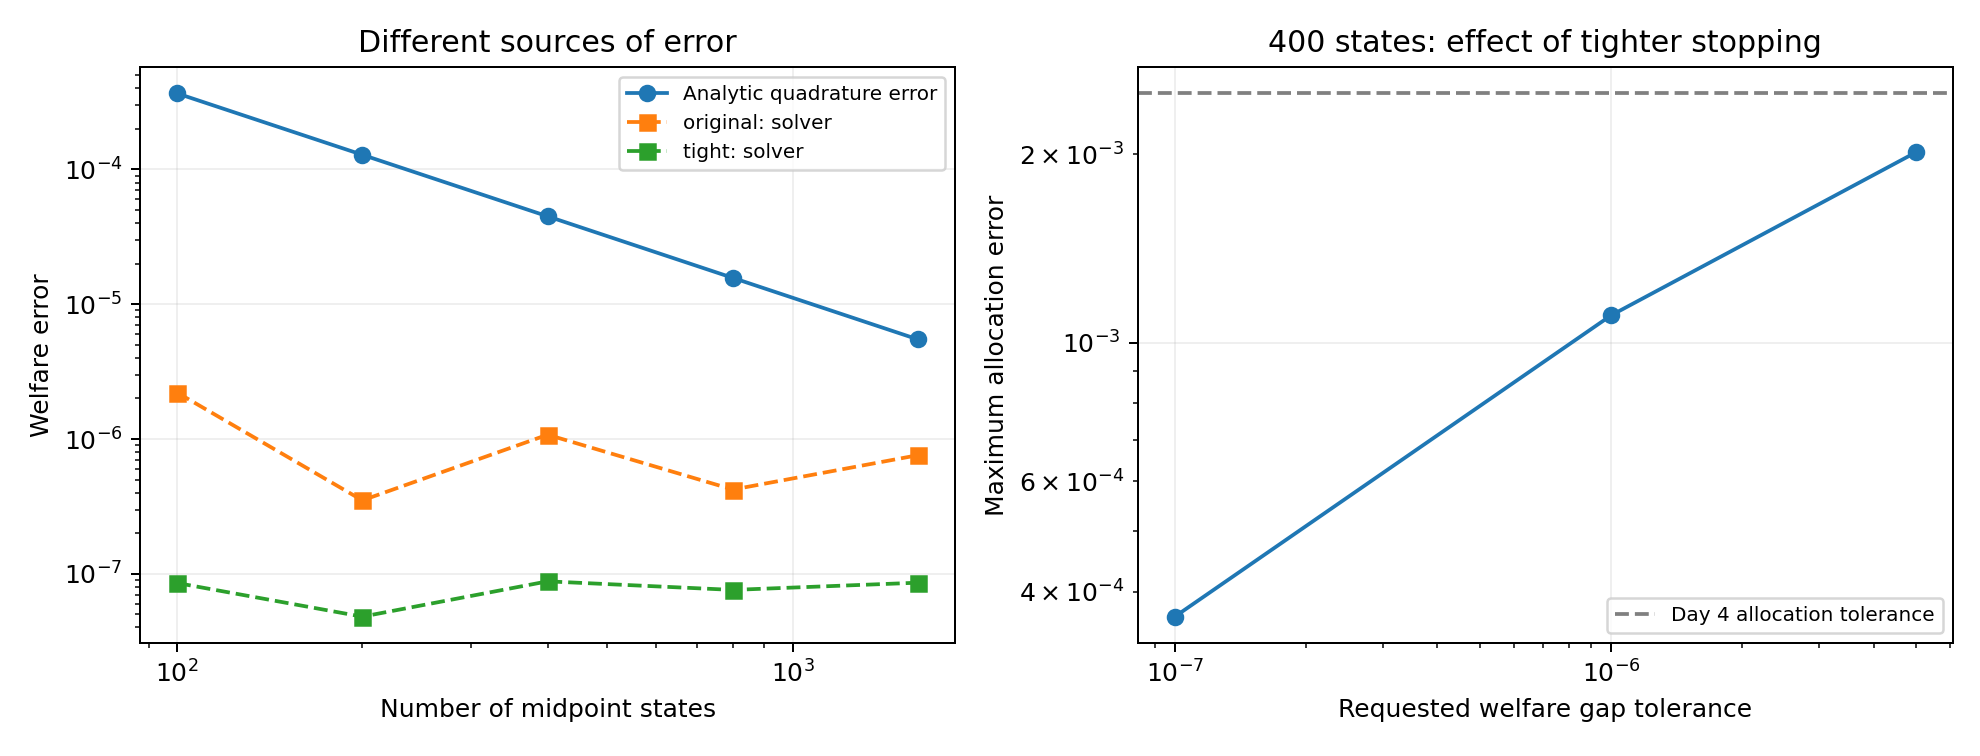

In [7]:
plot_path = output / 'stress_tests.png'
try:
    from IPython.display import Image, display
    display(Image(filename=str(plot_path)))
except ImportError:
    print('Plot saved:', plot_path)


## 8. Understand what we can claim
**Verified:** the stated concave Example 2 baseline, its finite-grid certificates, the tightened allocation comparisons, and the listed independent checks.

**Recorded limitations:** the original 800-state allocation miss and the harder alternative's convergence outcome. There is no rigorous continuous-distribution error certificate. Even the common evaluation grid has quadrature bias. The current global welfare-gap proof must not be reused for nonconcave preferences.

Parsa's separate personal review is not claimed. The accompanying research memo separates analytic results, finite-grid certificates and numerical evidence.

In [8]:
print((work / 'day05/RESEARCH_MEMO.md').read_text())


# Day 5 research memo

**Nouman Bashir | MUN Economics | 16 October 2026**

Prepared with ChatGPT/Codex assistance for the project led technically by Parsa
under Professor Lauzier. This is an assisted replication and audit, not a claim
of Parsa's separate personal verification.

## What was reproduced

The checked baseline solves the printed eight-agent logarithmic Example 2 of
Carlier and Lachapelle. Wealth is uniform on [0,1]; midpoint rank equals wealth
in this example, although code stores both separately. Each agent has Pareto
weight one. Five agents use log(1+sqrt(rank)+consumption), and three use
log(1+rank^(2/3)+consumption). Natural logarithms, probability weights, consumption
nonnegativity, statewise clearing and monotonicity are explicit.

The analytic benchmark assigns each h1 agent
b(s)=max((s+3(s^(2/3)-sqrt(s)))/8,0) and each h2 agent a(s)=(s-5b(s))/3.
The Day 4 derivation proves feasibility and activation near 0.298995684337.
Equal weighted marginal utilities and concavi

## 9. Save the sources and results
This creates a ZIP containing the source, research memo, settings, allocations, iteration histories and figure. Colab offers the download automatically. Save this executed notebook separately as well.

For a local rerun after extracting the ZIP: install `day05/requirements-verified.txt`, then run `python day05/day5_audit.py` from the extracted root.

In [9]:
from zipfile import ZipFile, ZIP_DEFLATED
archive = work.parent / 'Day_5_Run_Results.zip'
with ZipFile(archive, 'w', compression=ZIP_DEFLATED) as bundle:
    for path in sorted(work.rglob('*')):
        if path.is_file() and '__pycache__' not in path.parts:
            bundle.write(path, path.relative_to(work))
print('Saved:', archive)
try:
    from google.colab import files
except ImportError:
    files = None
if files is not None:
    files.download(str(archive))


Saved: /workspace/scratch/8e150a1c273e/day5_notebook_verification/Day_5_Run_Results.zip
